# Olist Historical Snapshot MLOps

## tl;dr
A reproducible CPU walkthrough of late-delivery classification from the original Olist dataset. It ports the project's SQL order-level aggregation to CSV/Pandas, then reuses the historical label, chronological split, feature transformations, preprocessing and eight-candidate LogisticRegression search.

**Interpretation:** this is an experimental historical-snapshot analysis. Final payment/item aggregates may contain information unavailable when an order was purchased. Real-time purchase-time inference has not been verified.

The executed tables below distinguish this rerun from the saved local model bundle. No model metrics are assumed in advance. The linked project's verified CI result is **172 passed, 1 warning**, with Ruff and Docker build passing.

[GitHub project](https://github.com/tahamohmadf19-dev/olist-mlops-project) Â· [Verified CI run](https://github.com/tahamohmadf19-dev/olist-mlops-project/actions/runs/42863988828)

Public release. Version 1 completed successfully on CPU. This visibility/prose save does not rerun training; the original executed version and recorded results remain version 1.


## Context & Methods

The six original notebooks provide the aggregation, labeling, chronological split, exploratory checks, feature engineering and classifier selection. This portable notebook retains the full feature recipe and all eight original model candidates.

1. Aggregate items, sellers, geolocation and payments to one row per order.
2. Restrict labels to delivered orders with known actual and estimated delivery dates. Late means the normalized actual delivery date is after the normalized estimate.
3. Sort by purchase timestamp; use a deterministic order-ID tie-breaker. Split rows 70%/15%/15% into train/validation/test.
4. Fit median imputation/scaling and categorical imputation/rare-category one-hot encoding on training data only.
5. Select LogisticRegression by validation average precision (called PR-AUC in the original project). Select the threshold by validation F1. Evaluate the untouched test period once.

### Key Assumptions
CSV inputs replace the local PostgreSQL connection. Multi-value categorical aggregates are sorted deterministically; the original SQL STRING_AGG did not specify an order. Runtime/library versions and these ordering details can change the fitted representation and metrics. This is a faithful portable adaptation of the methodology, not a claim of byte-for-byte artifact or feature parity.

The original local model and preprocessor are neither loaded nor replaced. No customer-level records, datasets or fitted model files are exported.


## Data

Source: **Olist, Brazilian E-Commerce Public Dataset** â€” [olistbr/brazilian-ecommerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

The source is licensed under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): attribution, noncommercial use and share-alike terms apply. The dataset is attached directly from its original Kaggle listing; it is not reuploaded. Derived tables and figures here retain that attribution and license. Changes comprise the CSV/Pandas port, deterministic aggregation/tie handling, and combined notebook presentation. No endorsement by Olist is implied.

Only aggregate diagnostics and evaluation results are displayed. Review text is not loaded.


In [1]:
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(42)
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "figure.dpi": 120,
})
COLORS = {"validation": "#246B8E", "test": "#AF6500", "neutral": "#59636E"}
print(json.dumps({
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scipy": scipy.__version__, "sklearn": sklearn.__version__,
    "compute": "CPU; no accelerators; no pip installations",
}, sort_keys=True))


{"compute": "CPU; no accelerators; no pip installations", "numpy": "2.5.4", "pandas": "3.1.0", "python": "3.12.10", "scipy": "1.18.1", "sklearn": "1.9.1"}


### 1. Load the attached source
All inputs come from the original dataset mount. Identifiers are used for validated joins only.


In [2]:
import os

# Kaggle mounts the dataset under /kaggle/input; OLIST_INPUT_DIR allows a local run.
input_root = Path(os.environ.get("OLIST_INPUT_DIR", "/kaggle/input"))
RUN_LABEL = "Kaggle rerun" if input_root == Path("/kaggle/input") else "Local rerun"
matches = sorted(input_root.rglob("olist_orders_dataset.csv"))
assert len(matches) == 1, "Attach only olistbr/brazilian-ecommerce as the data source."
DATA_ROOT = matches[0].parent
def load(name, **kwargs):
    path = DATA_ROOT / name
    assert path.is_file(), f"Required original CSV absent: {name}"
    return pd.read_csv(path, **kwargs)

orders = load("olist_orders_dataset.csv")
customers = load("olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": "string"})
items = load("olist_order_items_dataset.csv")
products = load("olist_products_dataset.csv")
translation = load("product_category_name_translation.csv")
sellers = load("olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": "string"})
geolocation = load(
    "olist_geolocation_dataset.csv",
    usecols=["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"],
    dtype={"geolocation_zip_code_prefix": "string"},
)
payments = load("olist_order_payments_dataset.csv")
for frame, key in ((orders, "order_id"), (customers, "customer_id"), (products, "product_id"), (sellers, "seller_id")):
    assert frame[key].notna().all() and frame[key].is_unique
assert translation["product_category_name"].is_unique
print("Original source loaded; order count:", len(orders))


Original source loaded; order count: 99441


### 2. Reproduce order-level aggregates
Join cardinality is checked explicitly. Numeric averages and counts follow the original SQL; distinct category strings use a documented deterministic ordering.


In [3]:
def distinct_text(values):
    unique = sorted(str(value) for value in pd.unique(values.dropna()))
    return " | ".join(unique) if unique else np.nan

def sql_sum(values):
    return values.sum(min_count=1)

geo = geolocation.groupby("geolocation_zip_code_prefix", as_index=False).agg(
    avg_lat=("geolocation_lat", "mean"), avg_lng=("geolocation_lng", "mean"),
)
assert geo["geolocation_zip_code_prefix"].notna().all()
product_dim = products.merge(translation, on="product_category_name", how="left", validate="many_to_one")
product_dim["product_category"] = product_dim["product_category_name_english"].combine_first(product_dim["product_category_name"])
seller_geo = geo.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix"})
item_rows = (
    items.merge(product_dim, on="product_id", how="left", validate="many_to_one")
    .merge(sellers, on="seller_id", how="left", validate="many_to_one")
    .merge(seller_geo, on="seller_zip_code_prefix", how="left", validate="many_to_one")
)
assert len(item_rows) == len(items)
item_agg = item_rows.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "size"),
    unique_product_count=("product_id", "nunique"),
    unique_seller_count=("seller_id", "nunique"),
    total_item_price=("price", sql_sum),
    avg_item_price=("price", "mean"),
    max_item_price=("price", "max"),
    total_freight_value=("freight_value", sql_sum),
    avg_product_weight_g=("product_weight_g", "mean"),
    avg_product_length_cm=("product_length_cm", "mean"),
    avg_product_height_cm=("product_height_cm", "mean"),
    avg_product_width_cm=("product_width_cm", "mean"),
    product_categories=("product_category", distinct_text),
    seller_states=("seller_state", distinct_text),
    seller_cities=("seller_city", distinct_text),
    avg_seller_lat=("avg_lat", "mean"),
    avg_seller_lng=("avg_lng", "mean"),
)
payment_agg = payments.groupby("order_id", as_index=False).agg(
    payment_record_count=("payment_type", "size"),
    payment_type_count=("payment_type", "nunique"),
    payment_types=("payment_type", distinct_text),
    max_payment_installments=("payment_installments", "max"),
    total_payment_value=("payment_value", sql_sum),
)
customer_geo = geo.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "avg_lat": "customer_lat", "avg_lng": "customer_lng",
})
joined = (
    orders.merge(customers, on="customer_id", how="left", validate="many_to_one")
    .merge(customer_geo, on="customer_zip_code_prefix", how="left", validate="many_to_one")
    .merge(item_agg, on="order_id", how="left", validate="one_to_one")
    .merge(payment_agg, on="order_id", how="left", validate="one_to_one")
)
raw_columns = [
    "order_id", "customer_id", "customer_unique_id", "order_status",
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
    "customer_zip_code_prefix", "customer_city", "customer_state", "customer_lat", "customer_lng",
    "item_count", "unique_product_count", "unique_seller_count",
    "total_item_price", "avg_item_price", "max_item_price", "total_freight_value",
    "avg_product_weight_g", "avg_product_length_cm", "avg_product_height_cm", "avg_product_width_cm",
    "product_categories", "seller_states", "seller_cities", "avg_seller_lat", "avg_seller_lng",
    "payment_record_count", "payment_type_count", "payment_types", "max_payment_installments", "total_payment_value",
]
joined = joined[raw_columns].copy()
assert len(joined) == len(orders) and joined["order_id"].is_unique
print("Join checks passed:", len(joined), "orders,", len(raw_columns), "original raw columns.")


Join checks passed: 99441 orders, 35 original raw columns.


### 3. Label and split chronologically
The label uses delivery dates at day granularity, matching Notebook 2. Excluded orders are not silently assigned an on-time label.


In [4]:
date_columns = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
for column in date_columns:
    joined[column] = pd.to_datetime(joined[column], errors="coerce")
eligible = (
    joined["order_status"].eq("delivered")
    & joined["order_delivered_customer_date"].notna()
    & joined["order_estimated_delivery_date"].notna()
)
labeled = joined.loc[eligible].copy()
assert labeled["order_purchase_timestamp"].notna().all()
actual = labeled["order_delivered_customer_date"].dt.normalize()
estimated = labeled["order_estimated_delivery_date"].dt.normalize()
labeled["is_late"] = (actual > estimated).astype("int8")
labeled["delivery_delay_days"] = (actual - estimated).dt.days
labeled = labeled.sort_values(["order_purchase_timestamp", "order_id"], kind="stable").reset_index(drop=True)

train_end = int(len(labeled) * 0.70)
validation_end = int(len(labeled) * (0.70 + 0.15))
train = labeled.iloc[:train_end].copy().reset_index(drop=True)
validation = labeled.iloc[train_end:validation_end].copy().reset_index(drop=True)
test = labeled.iloc[validation_end:].copy().reset_index(drop=True)
splits = {"Train": train, "Validation": validation, "Test": test}
assert sum(len(frame) for frame in splits.values()) == len(labeled)
assert train["order_purchase_timestamp"].max() <= validation["order_purchase_timestamp"].min()
assert validation["order_purchase_timestamp"].max() <= test["order_purchase_timestamp"].min()
for frame in splits.values():
    assert frame["is_late"].nunique() == 2
cohort = pd.DataFrame([
    {"split": name, "orders": len(frame), "late_orders": int(frame["is_late"].sum()),
     "late_rate": frame["is_late"].mean(), "first_purchase": frame["order_purchase_timestamp"].min(),
     "last_purchase": frame["order_purchase_timestamp"].max()}
    for name, frame in splits.items()
]).set_index("split")
print("Labeled orders:", len(labeled), "| Excluded unlabeled orders:", int((~eligible).sum()))
display(cohort.style.format({"orders": "{:,}", "late_orders": "{:,}", "late_rate": "{:.2%}"}))


Labeled orders: 96470 | Excluded unlabeled orders: 2971


,orders,late_orders,late_rate,first_purchase,last_purchase
split,,,,,
Train,"67,529","5,290",7.83%,2016-09-15 12:16:38,2018-04-15 20:12:35
Validation,"14,470",624,4.31%,2018-04-15 20:17:11,2018-06-21 08:29:29
Test,"14,471",620,4.28%,2018-06-21 08:41:07,2018-08-29 15:00:37


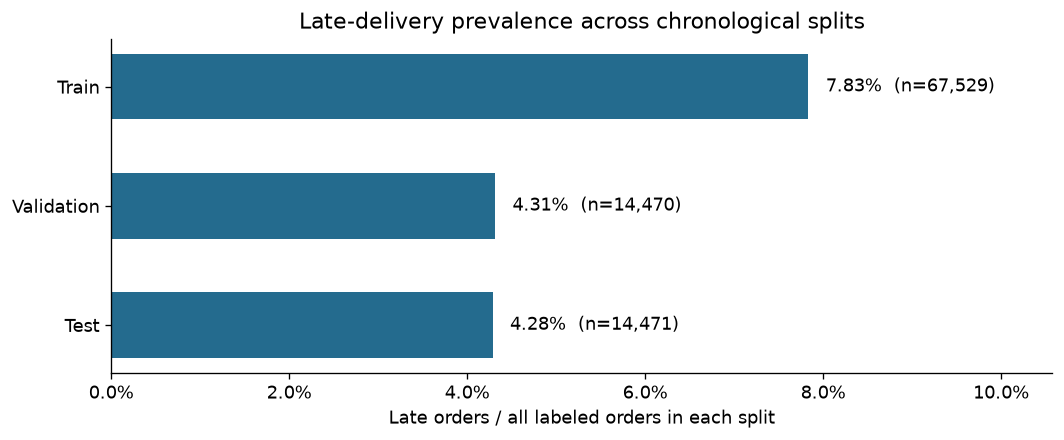

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(cohort.index, cohort["late_rate"], color=COLORS["validation"], height=0.55)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Late orders / all labeled orders in each split", title="Late-delivery prevalence across chronological splits")
ax.set_xlim(0, max(cohort["late_rate"]) * 1.35)
for bar, rate, count in zip(bars, cohort["late_rate"], cohort["orders"]):
    ax.text(rate + max(cohort["late_rate"]) * 0.025, bar.get_y() + bar.get_height()/2,
            f"{rate:.2%}  (n={count:,})", va="center")
fig.tight_layout()
plt.show()


## Results

### 4. Reuse the original feature transformations
The next cell embeds the project's deterministic feature module. Explicit future/target fields and identifiers are dropped. This does not prove the remaining historical aggregates were available at purchase time.


In [6]:
"""Deterministic feature engineering extracted from Notebook 5.

Keep feature names and transformations unchanged unless the notebook and
saved preprocessor are rebuilt together and parity tests are updated.
"""

from __future__ import annotations

import numpy as np
import pandas as pd

TARGET = "is_late"

LEAKAGE_COLUMNS = [
    "order_delivered_customer_date",
    "delivery_delay_days",
    "order_delivered_carrier_date",
    "order_approved_at",
    "order_status",
]

ID_COLUMNS = [
    "order_id",
    "customer_id",
    "customer_unique_id",
]

# ZIP prefix is a location identifier, not a continuous number.
# We already have state + latitude/longitude, so raw ZIP is dropped
# to avoid unnecessary high-cardinality encoding.
DROP_LOCATION_IDENTIFIER_COLUMNS = [
    "customer_zip_code_prefix",
]


# ============================================================
# 4. FEATURE ENGINEERING FUNCTIONS
# ============================================================

DATE_COLUMNS = [
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
]


def haversine_distance_km(
    lat1: pd.Series,
    lon1: pd.Series,
    lat2: pd.Series,
    lon2: pd.Series,
) -> pd.Series:
    """
    Calculate approximate great-circle distance in kilometers
    between customer and seller coordinates.
    """
    earth_radius_km = 6371.0088

    lat1_rad = np.radians(lat1.astype(float))
    lon1_rad = np.radians(lon1.astype(float))
    lat2_rad = np.radians(lat2.astype(float))
    lon2_rad = np.radians(lon2.astype(float))

    delta_lat = lat2_rad - lat1_rad
    delta_lon = lon2_rad - lon1_rad

    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(delta_lon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius_km * c


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Reproduce historical-snapshot features; scoring-time availability is unverified.
    """
    result = df.copy()

    # --------------------------------------------------------
    # Parse dates
    # --------------------------------------------------------

    for column in DATE_COLUMNS:
        if column in result.columns:
            result[column] = pd.to_datetime(
                result[column],
                format="mixed",
                errors="coerce",
            )

    # --------------------------------------------------------
    # Purchase-time features
    # --------------------------------------------------------

    purchase = result["order_purchase_timestamp"]

    result["purchase_year"] = purchase.dt.year
    result["purchase_month"] = purchase.dt.month
    result["purchase_day"] = purchase.dt.day
    result["purchase_weekday"] = purchase.dt.day_of_week
    result["purchase_hour"] = purchase.dt.hour
    result["purchase_is_weekend"] = (purchase.dt.day_of_week >= 5).astype("int8")

    # --------------------------------------------------------
    # Estimated delivery window
    # --------------------------------------------------------

    result["estimated_delivery_window_days"] = (
        result["order_estimated_delivery_date"] - result["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400.0

    # --------------------------------------------------------
    # Geographic distance
    # --------------------------------------------------------

    required_geo_columns = [
        "customer_lat",
        "customer_lng",
        "avg_seller_lat",
        "avg_seller_lng",
    ]

    if all(column in result.columns for column in required_geo_columns):
        result["customer_seller_distance_km"] = haversine_distance_km(
            result["customer_lat"],
            result["customer_lng"],
            result["avg_seller_lat"],
            result["avg_seller_lng"],
        )

    # --------------------------------------------------------
    # Log features for strongly right-skewed variables
    # --------------------------------------------------------

    skewed_columns = [
        "total_item_price",
        "avg_item_price",
        "max_item_price",
        "total_freight_value",
        "avg_product_weight_g",
        "total_payment_value",
    ]

    for column in skewed_columns:
        if column in result.columns:
            result[f"log1p_{column}"] = np.log1p(result[column].clip(lower=0))

    # --------------------------------------------------------
    # Drop raw dates after extracting useful features
    # --------------------------------------------------------

    result = result.drop(
        columns=[column for column in DATE_COLUMNS if column in result.columns],
        errors="ignore",
    )

    # --------------------------------------------------------
    # Remove leakage, IDs, and raw ZIP identifier
    # --------------------------------------------------------

    result = result.drop(
        columns=[
            *LEAKAGE_COLUMNS,
            *ID_COLUMNS,
            *DROP_LOCATION_IDENTIFIER_COLUMNS,
        ],
        errors="ignore",
    )

    return result


### 5. Fit preprocessing on training data only
Median imputation and scaling for numeric fields; constant imputation and one-hot encoding with min_frequency=20 for categories, as in Notebook 5.


In [7]:
engineered = {name: engineer_features(frame) for name, frame in splits.items()}
features = {name: frame.drop(columns=["is_late"]) for name, frame in engineered.items()}
labels = {name: frame["is_late"].to_numpy(dtype=np.int8) for name, frame in engineered.items()}
X_train = features["Train"]
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
assert set(numeric_features) | set(categorical_features) == set(X_train.columns)
assert not set(LEAKAGE_COLUMNS + ID_COLUMNS + DATE_COLUMNS + [TARGET]) & set(X_train.columns)
for frame in features.values():
    for name in categorical_features:
        frame[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=True)),
])
preprocessor = ColumnTransformer(
    [("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)],
    remainder="drop", sparse_threshold=1.0,
)
matrices = {"Train": sparse.csr_matrix(preprocessor.fit_transform(features["Train"]))}
for name in ("Validation", "Test"):
    matrices[name] = sparse.csr_matrix(preprocessor.transform(features[name]))
for name, matrix in matrices.items():
    assert np.isfinite(matrix.data).all()
    print(name, "matrix shape:", matrix.shape)
print("Raw model features:", len(numeric_features), "numeric +", len(categorical_features), "categorical")


Train matrix shape: (67529, 821)
Validation matrix shape: (14470, 821)
Test matrix shape: (14471, 821)
Raw model features: 33 numeric + 6 categorical


### 6. Select the model and threshold on validation only
The original eight combinations are retained. Average precision is the selection score; the test period is not used to choose parameters or threshold.


In [8]:
def classification_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_probability: np.ndarray,
) -> dict[str, float]:
    """
    Calculate classification metrics suitable for an imbalanced
    binary classification problem.
    """

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "precision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "roc_auc": float(
            roc_auc_score(
                y_true,
                y_probability,
            )
        ),
        "pr_auc": float(
            average_precision_score(
                y_true,
                y_probability,
            )
        ),
    }


In [9]:
C_VALUES = [0.01, 0.1, 1.0, 10.0]
CLASS_WEIGHTS = [None, 'balanced']

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(matrices["Train"], labels["Train"])
baseline_val_probability = baseline_model.predict_proba(matrices["Validation"])[:, 1]
baseline_val_metrics = classification_metrics(
    labels["Validation"], baseline_model.predict(matrices["Validation"]), baseline_val_probability,
)
best_pr_auc = -np.inf
search_results = []
for class_weight in CLASS_WEIGHTS:
    for c_value in C_VALUES:
        candidate = LogisticRegression(
            C=c_value, class_weight=class_weight, solver="liblinear",
            max_iter=3000, random_state=42,
        )
        candidate.fit(matrices["Train"], labels["Train"])
        probability = candidate.predict_proba(matrices["Validation"])[:, 1]
        candidate_metrics = classification_metrics(
            labels["Validation"], (probability >= 0.5).astype("int8"), probability,
        )
        search_results.append({"C": c_value, "class_weight": str(class_weight), **candidate_metrics})
        if candidate_metrics["pr_auc"] > best_pr_auc:
            best_pr_auc = candidate_metrics["pr_auc"]
            best_model = candidate
            best_validation_probability = probability
            best_parameters = {"C": c_value, "class_weight": class_weight}
display(pd.DataFrame(search_results).sort_values("pr_auc", ascending=False).reset_index(drop=True).round(5))

precision_values, recall_values, thresholds = precision_recall_curve(
    labels["Validation"], best_validation_probability,
)
f1_values = 2 * precision_values[:-1] * recall_values[:-1] / (
    precision_values[:-1] + recall_values[:-1] + 1e-12
)
best_threshold = float(thresholds[int(np.argmax(f1_values))])
validation_prediction = (best_validation_probability >= best_threshold).astype("int8")
validation_metrics = classification_metrics(labels["Validation"], validation_prediction, best_validation_probability)
print("Selected on validation only:", best_parameters, "| threshold:", best_threshold)


,C,class_weight,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,1.00,None,0.94623,0.52734,0.17917,0.06891,0.09954,0.74602,0.12514
1,0.10,None,0.94990,0.51778,0.17834,0.04487,0.07170,0.75471,0.12499
2,10.00,None,0.94464,0.53034,0.17582,0.07692,0.10702,0.73863,0.12349
3,0.01,None,0.95515,0.50292,0.14286,0.00801,0.01517,0.75601,0.12265
4,0.01,balanced,0.36006,0.63271,0.05930,0.93109,0.11149,0.75311,0.11993
5,0.10,balanced,0.41279,0.64189,0.06198,0.89263,0.11591,0.74670,0.11947
6,1.00,balanced,0.42923,0.63519,0.06166,0.86058,0.11508,0.73715,0.11884
7,10.00,balanced,0.43214,0.63594,0.06186,0.85897,0.11541,0.73318,0.11640


Selected on validation only: {'C': 1.0, 'class_weight': None} | threshold: 0.33907550456666385


### 7. Evaluate the untouched test period
Historical local-bundle metrics below are read-only reference values from the verified saved summary. Rerun metrics are calculated by this execution. Differences are reported rather than presented as artifact parity. Average precision is not trapezoidal integration of the plotted precision-recall curve.


In [10]:
historical_bundle = {'best_parameters': {'C': 1.0, 'class_weight': 'None'}, 'selected_threshold': 0.3389565594999209, 'baseline_validation_metrics': {'accuracy': 0.9568762957843815, 'balanced_accuracy': 0.5, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5, 'pr_auc': 0.04312370421561852}, 'best_validation_metrics': {'accuracy': 0.9071872840359364, 'balanced_accuracy': 0.6064103258554725, 'precision': 0.1624413145539906, 'recall': 0.27724358974358976, 'f1': 0.20485494375370042, 'roc_auc': 0.7461258828801801, 'pr_auc': 0.12503445098512253}, 'test_metrics': {'accuracy': 0.7251744869048442, 'balanced_accuracy': 0.5567689883809483, 'precision': 0.060487038491751764, 'recall': 0.3725806451612903, 'f1': 0.10407749493129083, 'roc_auc': 0.6112310512109292, 'pr_auc': 0.06704183316928577}}

test_probability = best_model.predict_proba(matrices["Test"])[:, 1]
test_prediction = (test_probability >= best_threshold).astype("int8")
test_metrics = classification_metrics(labels["Test"], test_prediction, test_probability)
records = [
    {"run": "Saved local bundle / validation", **historical_bundle["best_validation_metrics"]},
    {"run": "Saved local bundle / test", **historical_bundle["test_metrics"]},
    {"run": "Majority baseline / validation", **baseline_val_metrics},
    {"run": f"{RUN_LABEL} / validation", **validation_metrics},
    {"run": f"{RUN_LABEL} / test", **test_metrics},
]
result_table = pd.DataFrame(records).set_index("run")
display(result_table[["pr_auc", "roc_auc", "balanced_accuracy", "precision", "recall", "f1"]].round(5))
cm = confusion_matrix(labels["Test"], test_prediction, labels=[0, 1])
display(pd.DataFrame(cm, index=["Actual on time", "Actual late"], columns=["Predicted on time", "Predicted late"]))
display(Markdown(
    f"**Observed {RUN_LABEL.lower()}:** test average precision = **{test_metrics['pr_auc']:.4f}**, "
    f"test F1 = **{test_metrics['f1']:.4f}**, recall = **{test_metrics['recall']:.4f}**. "
    f"The threshold **{best_threshold:.4f}** was selected on validation data, not test data."
))


,pr_auc,roc_auc,balanced_accuracy,precision,recall,f1
run,,,,,,
Saved local bundle / validation,0.12503,0.74613,0.60641,0.16244,0.27724,0.20485
Saved local bundle / test,0.06704,0.61123,0.55677,0.06049,0.37258,0.10408
Majority baseline / validation,0.04312,0.50000,0.50000,0.00000,0.00000,0.00000
Local rerun / validation,0.12514,0.74602,0.60663,0.16336,0.27724,0.20559
Local rerun / test,0.06704,0.61152,0.55702,0.06060,0.37258,0.10424


,Predicted on time,Predicted late
Actual on time,10270,3581
Actual late,389,231


**Observed local rerun:** test average precision = **0.0670**, test F1 = **0.1042**, recall = **0.3726**. The threshold **0.3391** was selected on validation data, not test data.

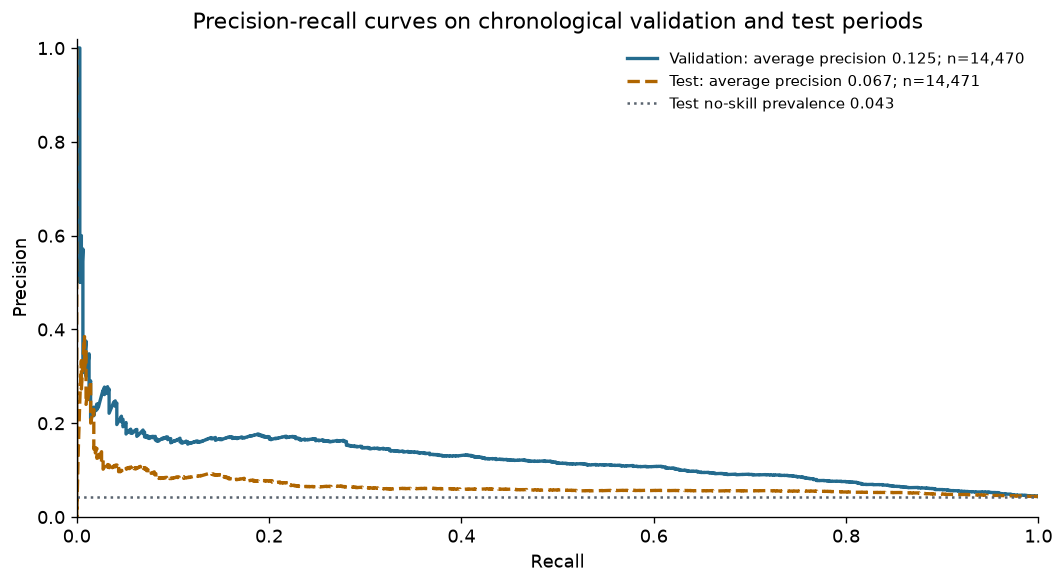

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, y, probability, color, style in (
    ("Validation", labels["Validation"], best_validation_probability, COLORS["validation"], "-"),
    ("Test", labels["Test"], test_probability, COLORS["test"], "--"),
):
    precision, recall, _ = precision_recall_curve(y, probability)
    average_precision = average_precision_score(y, probability)
    ax.plot(recall, precision, linestyle=style, color=color, linewidth=2,
            label=f"{name}: average precision {average_precision:.3f}; n={len(y):,}")
ax.axhline(labels["Test"].mean(), color=COLORS["neutral"], linestyle=":", linewidth=1.5,
           label=f"Test no-skill prevalence {labels['Test'].mean():.3f}")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves on chronological validation and test periods",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="upper right", fontsize=9, frameon=False)
fig.tight_layout()
plt.show()


## Takeaways

- Read observed metrics relative to class prevalence, not accuracy alone. The untouched test period is the relevant out-of-time check; a temporal split does not remove leakage from final historical aggregates.
- The rerun refits the original eight-candidate method on the attached CSVs. It does not load, replace, export or certify the local inference bundle.
- Payment/item aggregates and delivery estimates have unverified scoring-time availability. Real-time purchase-time inference remains unverified, even with explicit future fields removed.
- GitHub demonstrates the inference API, semantic validation, tests, Docker and monitoring. Its source-only CI does not prove a clean clone can serve predictions: the DVC remote is unavailable, and model/preprocessing artifacts are intentionally not in Git.
- No raw dataset, per-order predictions, identifiers or fitted model binaries are exported here. CPU execution uses the attached original source; no paid resources are requested.

### Reproducibility
Use the attached original dataset and Run All, from imports through the final verification cell. The dataset's current mounted version and installed library versions determine this rerun. The source notebooks, saved-bundle reference and GitHub CI are distinct evidence sources; their results are not interchangeable.


In [12]:
verification = {
    "source_dataset": "olistbr/brazilian-ecommerce",
    "source_license": "CC BY-NC-SA 4.0",
    "labeled_orders": int(len(labeled)),
    "split_rows": {name: int(len(frame)) for name, frame in splits.items()},
    "transformed_features": int(matrices["Train"].shape[1]),
    "candidate_count": len(search_results),
    "best_parameters": best_parameters,
    "validation_selected_threshold": best_threshold,
    "validation_metrics": validation_metrics,
    "test_metrics": test_metrics,
    "compute": "CPU",
    "github_verified_tests": "172 passed, 1 warning",
    "github_ci_run": "42863988828",
    "serialization_or_data_export": False,
}
assert len(search_results) == 8
assert len(preprocessor.get_feature_names_out()) == matrices["Train"].shape[1]
assert all(np.isfinite(list(metrics.values())).all() for metrics in (validation_metrics, test_metrics))
print("OLIST_KAGGLE_EXECUTION_RESULT=" + json.dumps(verification, sort_keys=True))


OLIST_KAGGLE_EXECUTION_RESULT={"best_parameters": {"C": 1.0, "class_weight": null}, "candidate_count": 8, "compute": "CPU", "github_ci_run": "42863988828", "github_verified_tests": "172 passed, 1 warning", "labeled_orders": 96470, "serialization_or_data_export": false, "source_dataset": "olistbr/brazilian-ecommerce", "source_license": "CC BY-NC-SA 4.0", "split_rows": {"Test": 14471, "Train": 67529, "Validation": 14470}, "test_metrics": {"accuracy": 0.7256582129776795, "balanced_accuracy": 0.5570216777174584, "f1": 0.10424187725631769, "pr_auc": 0.06704352398446158, "precision": 0.06059811122770199, "recall": 0.3725806451612903, "roc_auc": 0.611524962678833}, "transformed_features": 821, "validation_metrics": {"accuracy": 0.9076019350380097, "balanced_accuracy": 0.6066269949295733, "f1": 0.20558526440879382, "pr_auc": 0.12514229622222273, "precision": 0.16336166194523136, "recall": 0.27724358974358976, "roc_auc": 0.746019400215558}, "validation_selected_threshold": 0.33907550456666385}
